<a href="https://colab.research.google.com/github/erlinncacev-bot/A2-Time-Series-Forecasting-LSTM/blob/main/Beijing_Air_Quality_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Load the Beijing Air Quality dataset
URL = "https://archive.ics.uci.edu/static/public/381/data.csv"

raw = pd.read_csv(URL)

# Clean the column names
raw.columns = raw.columns.str.strip()

# Display the first five rows
raw.head()

,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0


In [ ]:
# Task 1: Audit the Raw Data

raw.info()

print("\nSummary statistics:")
display(raw.describe().T)

print("\nMissing values in each column:")
print(raw.isna().sum())

print("\nWind direction counts:")
print(raw["cbwd"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   No      43824 non-null  int64  
 1   year    43824 non-null  int64  
 2   month   43824 non-null  int64  
 3   day     43824 non-null  int64  
 4   hour    43824 non-null  int64  
 5   pm2.5   41757 non-null  float64
 6   DEWP    43824 non-null  int64  
 7   TEMP    43824 non-null  float64
 8   PRES    43824 non-null  float64
 9   cbwd    43824 non-null  object 
 10  Iws     43824 non-null  float64
 11  Is      43824 non-null  int64  
 12  Ir      43824 non-null  int64  
dtypes: float64(4), int64(8), object(1)
memory usage: 4.3+ MB

Summary statistics:


,count,mean,std,min,25%,50%,75%,max
No,43824.0,21912.500000,12651.043435,1.00,10956.75,21912.50,32868.25,43824.0
year,43824.0,2012.000000,1.413842,2010.00,2011.00,2012.00,2013.00,2014.0
month,43824.0,6.523549,3.448572,1.00,4.00,7.00,10.00,12.0
day,43824.0,15.727820,8.799425,1.00,8.00,16.00,23.00,31.0
hour,43824.0,11.500000,6.922266,0.00,5.75,11.50,17.25,23.0
pm2.5,41757.0,98.613215,92.050387,0.00,29.00,72.00,137.00,994.0
DEWP,43824.0,1.817246,14.433440,-40.00,-10.00,2.00,15.00,28.0
TEMP,43824.0,12.448521,12.198613,-19.00,2.00,14.00,23.00,42.0
PRES,43824.0,1016.447654,10.268698,991.00,1008.00,1016.00,1025.00,1046.0
Iws,43824.0,23.889140,50.010635,0.45,1.79,5.37,21.91,585.6



Missing values in each column:
No          0
year        0
month       0
day         0
hour        0
pm2.5    2067
DEWP        0
TEMP        0
PRES        0
cbwd        0
Iws         0
Is          0
Ir          0
dtype: int64

Wind direction counts:
cbwd
SE    15290
NW    14150
cv     9387
NE     4997
Name: count, dtype: int64


Q1. How many rows are there? If the data covers 1 Jan 2010 to 31 Dec 2014 hourly, how many rows should there be?

Answer:
There are 43,824 rows. This is the expected number of hourly observations from January 1, 2010, through December 31, 2014, including leap year 2012.

Q2. Which columns have missing values, and what percentage of each is missing?

Answer:
Only the pm2.5 column has missing values. It has 2,067 missing values, which is approximately 4.72% of the 43,824 rows. All other columns have no missing values.

Q3. The timestamp is split across four columns. What problems could this cause if rows were shuffled or if one column had errors?

Answer:
If rows were shuffled, the data would no longer be in chronological order, making time-based analysis and forecasting unreliable. Errors in the year, month, day, or hour columns could create incorrect timestamps, missing time periods, or duplicate timestamps.

Q4. Which columns are instantaneous measurements and which are cumulative?

Answer:
pm2.5, DEWP, TEMP, and PRES are instantaneous measurements. Iws, Is, and Ir are cumulative measurements. cbwd is a categorical variable that records wind direction.

In [ ]:
# Create a datetime column
raw["datetime"] = pd.to_datetime(
    raw[["year", "month", "day", "hour"]]
)

# Set datetime as the index
df = raw.set_index("datetime").sort_index()

# Check the datetime index
print("Index is unique:", df.index.is_unique)
print("Index is chronological:", df.index.is_monotonic_increasing)

# Check for missing hourly timestamps
full_index = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="h"
)

missing_hours = full_index.difference(df.index)

print("Expected hourly timestamps:", len(full_index))
print("Missing timestamps:", len(missing_hours))

# Check for duplicate timestamps
print("Duplicate timestamps:", df.index.duplicated().sum())

Index is unique: True
Index is chronological: True
Expected hourly timestamps: 43824
Missing timestamps: 0
Duplicate timestamps: 0


Q5. Is the index unique and complete? Why run the checks?

Yes, the datetime index is unique, chronological, and complete. The dataset contains 43,824 expected hourly timestamps, with zero missing timestamps and zero duplicate timestamps. These checks ensure that every hour has exactly one timestamp and that the observations are arranged in the correct chronological order. This is important for accurate time series analysis and forecasting.

Q6. What time zone assumption are you making, and how could a wrong assumption affect daily cycles?

I assume that the timestamps represent local time in Beijing, China, because the dataset contains air quality measurements from Beijing. If the time zone assumption is incorrect, observations may be assigned to the wrong hours of the day. This could affect the analysis of daily pollution patterns and the accuracy of forecasting models.

In [ ]:
# Count missing PM2.5 readings
missing = df["pm2.5"].isna()

print("Missing PM2.5 readings:", missing.sum())
print("Missing percentage:", round(missing.mean() * 100, 2), "%")

# Find consecutive missing-value gaps
groups = missing.ne(missing.shift()).cumsum()

gap_lengths = (
    missing[missing]
    .groupby(groups[missing])
    .size()
)

print("Longest missing gap:", gap_lengths.max(), "hours")

Missing PM2.5 readings: 2067
Missing percentage: 4.72 %
Longest missing gap: 155 hours


Q7. What percentage of PM2.5 is missing, and what is the longest gap?

The PM2.5 column has 2,067 missing values, representing 4.72% of the total observations. The longest consecutive gap is 155 hours, or approximately 6.5 days. This indicates that some missing values occur in long periods rather than as isolated missing readings.

In [ ]:
# Step 3: Evaluate with a masking experiment

rng = np.random.default_rng(0)

known = df["pm2.5"].dropna().index
hide = rng.choice(known, size=500, replace=False)

test = df["pm2.5"].copy()
test.loc[hide] = np.nan

# Compare three filling methods
seasonal_median = df.groupby(
    [df.index.month, df.index.hour]
)["pm2.5"].transform("median")

fills = {
    "ffill": test.ffill(limit=6),
    "interp": test.interpolate(method="time", limit=6),
    "seasonal": test.fillna(seasonal_median)
}

# Calculate RMSE for each method
for name, filled in fills.items():
    err = (filled.loc[hide] - df.loc[hide, "pm2.5"]).dropna()

    print(
        f"{name:9s} RMSE={np.sqrt((err**2).mean()):6.1f} "
        f"filled={len(err)}/{len(hide)}"
    )

ffill     RMSE=  41.1 filled=498/500
interp    RMSE=  22.3 filled=498/500
seasonal  RMSE= 103.7 filled=500/500


Question 8. Which method had the lowest RMSE in the masking test? Why might this experiment overstate how good interpolation is on real gaps?

Answer:

Interpolation had the lowest RMSE of 22.3, followed by forward fill at 41.1 and seasonal median at 103.7. Therefore, interpolation performed best in the masking test, although it successfully filled only 498 of the 500 masked values.
This experiment may overstate the accuracy of interpolation because randomly masked values are usually surrounded by known observations. In real situations, missing values may occur in long consecutive gaps, making interpolation less accurate because fewer neighboring observations are available.

In [ ]:
# Q9: Test what happens when limit=6 is removed

# Forward Fill without a limit
ffill_unlimited = df["pm2.5"].ffill()

# Time Interpolation without a limit
interp_unlimited = df["pm2.5"].interpolate(
    method="time"
)

# Seasonal Median without a limit
seasonal_median = df.groupby(
    [df.index.month, df.index.hour]
)["pm2.5"].transform("median")

seasonal_unlimited = df["pm2.5"].fillna(
    seasonal_median
)

# Compare the number of missing values
print("Missing values after removing limit=6:")

print("Forward Fill:", ffill_unlimited.isna().sum())
print("Interpolation:", interp_unlimited.isna().sum())
print("Seasonal Median:", seasonal_unlimited.isna().sum())

Missing values after removing limit=6:
Forward Fill: 24
Interpolation: 24
Seasonal Median: 0


Q9. Why did we set limit=6? What happens to a 3-day outage under each method if the limit is removed?

We set limit=6 to restrict the filling of missing values to a maximum of six consecutive hours. This prevents unreliable estimates during long periods of missing data.

If the limit is removed, a 3-day outage (72 consecutive missing hours) will be handled differently by each method:

1. Forward Fill: The last available PM2.5 reading is carried forward for all 72 hours.
2. Time Interpolation: Missing values are estimated by connecting the readings before and after the outage. This assumes a gradual change in pollution levels.
3. Seasonal Median: Missing values are replaced with typical PM2.5 readings for the corresponding month and hour.

Removing the limit allows all three methods to fill longer gaps, but the resulting values may not represent actual pollution conditions. Forward fill and interpolation may produce misleading estimates during long outages, while seasonal median may fail to capture unusual pollution events.

Q10. When would the pm25_missing indicator column be useful?

The pm25_missing indicator column is useful for identifying which PM2.5 values were originally missing and later filled using imputation methods. It helps distinguish actual measurements from estimated values.

This indicator is important when analyzing air quality patterns and training forecasting models because imputed values may not accurately represent actual pollution levels. It also allows us to evaluate whether missing data affects the accuracy of our analysis and predictions.

Available columns:
['No', 'year', 'month', 'day', 'hour', 'pm2.5', 'DEWP', 'TEMP', 'PRES', 'cbwd', 'Iws', 'Is', 'Ir']

Domain rule checks:
Dew point above temperature: 1
Flagged hours: 239


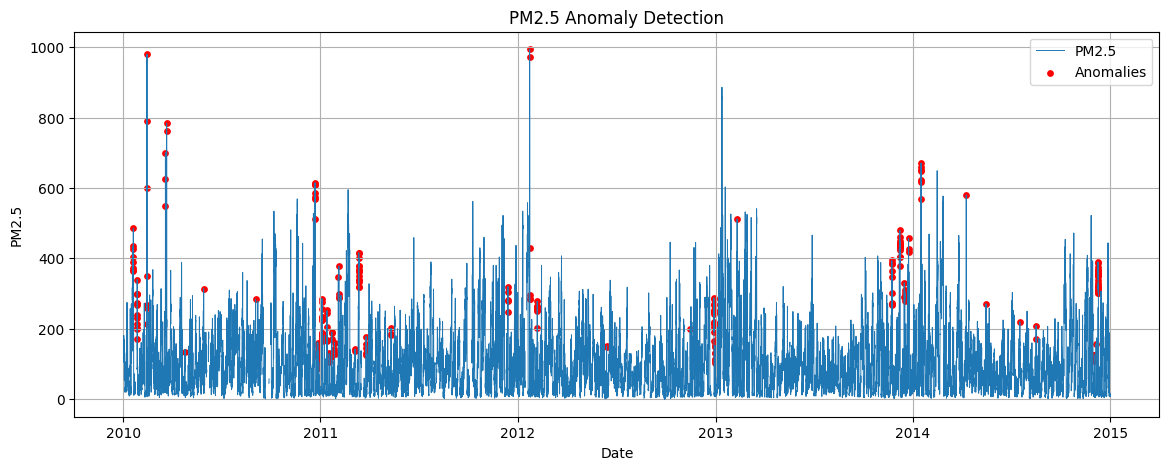


Five flagged hours:
                     TEMP  DEWP    PRES
datetime                               
2010-01-18 20:00:00  -2.0    -5  1026.0
2010-01-19 18:00:00   1.0    -3  1018.0
2010-01-19 19:00:00   2.0    -3  1020.0
2010-01-19 20:00:00   1.0    -3  1020.0
2010-01-19 21:00:00   0.0    -3  1021.0

PM2.5 values at flagged hours:
datetime
2010-01-18 20:00:00    435.0
2010-01-19 18:00:00    485.0
2010-01-19 19:00:00    426.0
2010-01-19 20:00:00    403.0
2010-01-19 21:00:00    374.0
Name: pm25_interp, dtype: float64


In [ ]:

# TASK 4: ANOMALY CHECKS

import numpy as np
import matplotlib.pyplot as plt

# Step 1: Find the correct PM2.5 column names
columns = df.columns.tolist()

print("Available columns:")
print(columns)

# Find the interpolated PM2.5 column
interp_candidates = ["pm25_interp", "pm2.5_interp"]

interp_col = next(
    (col for col in interp_candidates if col in df.columns),
    None
)

# If the interpolated column is missing, create it
if interp_col is None:

    raw_candidates = ["pm25", "pm2.5"]

    raw_col = next(
        (col for col in raw_candidates if col in df.columns),
        None
    )

    if raw_col is None:
        raise ValueError(
            "Cannot find the PM2.5 column. "
            "Check the printed column names."
        )

    df["pm25_interp"] = df[raw_col].interpolate(
        method="time",
        limit=6
    )

    interp_col = "pm25_interp"

# Use the correct interpolated series
s = df[interp_col]

# Step 2: Domain rules
print("\nDomain rule checks:")

print(
    "Dew point above temperature:",
    (df["DEWP"] > df["TEMP"]).sum()
)

# Step 3: Robust statistical rule
win = 24 * 7

med = s.rolling(
    win,
    center=True,
    min_periods=24
).median()

resid = s - med

mad = resid.abs().rolling(
    win,
    center=True,
    min_periods=24
).median().replace(0, np.nan)

robust_z = 0.6745 * resid / mad

# Flag anomalies using threshold of 6
df["pm25_flag"] = (
    robust_z.abs() > 6
).astype(int)

print(
    "Flagged hours:",
    df["pm25_flag"].sum()
)

# Step 4: Plot anomalies
plt.figure(figsize=(14, 5))

plt.plot(
    df.index,
    s,
    label="PM2.5",
    linewidth=0.7
)

flagged = df["pm25_flag"] == 1

plt.scatter(
    df.index[flagged],
    s[flagged],
    color="red",
    s=15,
    label="Anomalies"
)

plt.title("PM2.5 Anomaly Detection")
plt.xlabel("Date")
plt.ylabel("PM2.5")
plt.legend()
plt.grid(True)
plt.show()

# Step 5: Inspect five flagged hours
print("\nFive flagged hours:")

print(
    df.loc[
        flagged,
        ["TEMP", "DEWP", "PRES"]
    ].head(5)
)

print("\nPM2.5 values at flagged hours:")
print(s[flagged].head(5))


Q11. Do any physical-range violations exist? What would you do with them?
Answer: Yes. There is one hour when the dew point is higher than the temperature, which is physically unusual. I would investigate the value. If it is a sensor or recording error, I would correct or remove it; if it is valid, I would retain it.

Q12. Inspect five flagged hours. Do they look like sensor glitches or genuine pollution episodes? Would you remove them? Justify your decision for a forecasting use case and for a describing air quality use case.
Answer: The five flagged hours have unusually high PM2.5 values, but that alone does not prove they are sensor glitches. I would inspect the surrounding readings and other weather measurements. For forecasting, I would correct or remove values only if they are confirmed errors. For describing air quality, I would keep values that represent genuine pollution episodes so the analysis reflects actual conditions.

In [ ]:
df["pm25_flag_3_5"] = (robust_z.abs() > 3.5).astype(int)
print("Flagged hours at threshold 3.5:", df["pm25_flag_3_5"].sum())

Flagged hours at threshold 3.5: 1041


Q13. Change the threshold from 6 to 3.5. How does the count change, and what does that tell you about choosing thresholds?
Answer: Lowering the threshold from 6 to 3.5 increases the number of flagged hours from 239 to 1,041. This shows that a lower threshold identifies more possible anomalies, but may also flag more normal variation. The threshold should be chosen carefully based on the purpose of the analysis and whether false alarms or missed anomalies are more costly.

array([<Axes: xlabel='datetime'>, <Axes: xlabel='datetime'>,
       <Axes: xlabel='datetime'>], dtype=object)

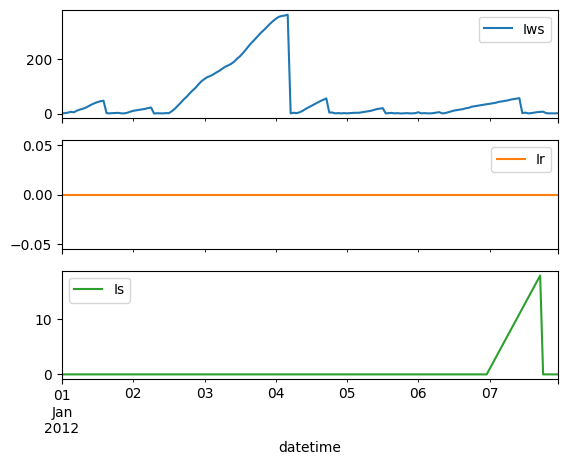

In [ ]:
df.loc["2012-01-01":"2012-01-07", ["Iws", "Ir", "Is"]].plot(subplots=True)

In [ ]:
daily = df.resample("D").agg(
    pm25_mean=("pm2.5", "mean"),
    pm25_max=("pm25_interp", "max"),
    temp=("TEMP", "mean"),
    pres=("PRES", "mean"),
    iws_max=("Iws", "max"),
    rain_hrs=("Ir", "max"),
    snow_hrs=("Is", "max"),
)

valid_hours = df["pm2.5"].resample("D").count()
daily.loc[valid_hours < 18, "pm25_mean"] = np.nan

print(daily.head())
print(daily["pm25_mean"].isna().sum(), "days without a valid mean")

             pm25_mean  pm25_max       temp         pres  iws_max  rain_hrs  \
datetime                                                                      
2010-01-01         NaN       NaN  -6.750000  1017.083333    43.82         0   
2010-01-02  145.958333     181.0  -5.125000  1024.750000    55.43         0   
2010-01-03   78.833333     107.0  -8.541667  1022.791667   127.84         0   
2010-01-04   31.333333      79.0 -11.500000  1029.291667   198.45         0   
2010-01-05   42.458333     106.0 -14.458333  1033.625000   218.57         0   

            snow_hrs  
datetime              
2010-01-01         0  
2010-01-02         4  
2010-01-03        27  
2010-01-04         0  
2010-01-05         0  
104 days without a valid mean


Q14. What does the plot of Iws show about how it behaves over time? Why would mean or sum be a poor way to aggregate it to daily values?

Answer: The Iws plot shows that wind speed changes over time, with periods of gradual increase and sudden drops. A daily mean hides short periods of strong wind and other within-day changes. A sum is not appropriate because wind speed is not an amount that should be added across hours.

Q15. What is the purpose of the validity rule (valid_hours < 18)? How many days does it affect?

Answer: The rule requires at least 18 valid hourly PM2.5 readings before calculating a daily mean. It prevents daily averages based on too few observations from being misleading. It affects 104 days, which have no valid daily mean after applying the rule.

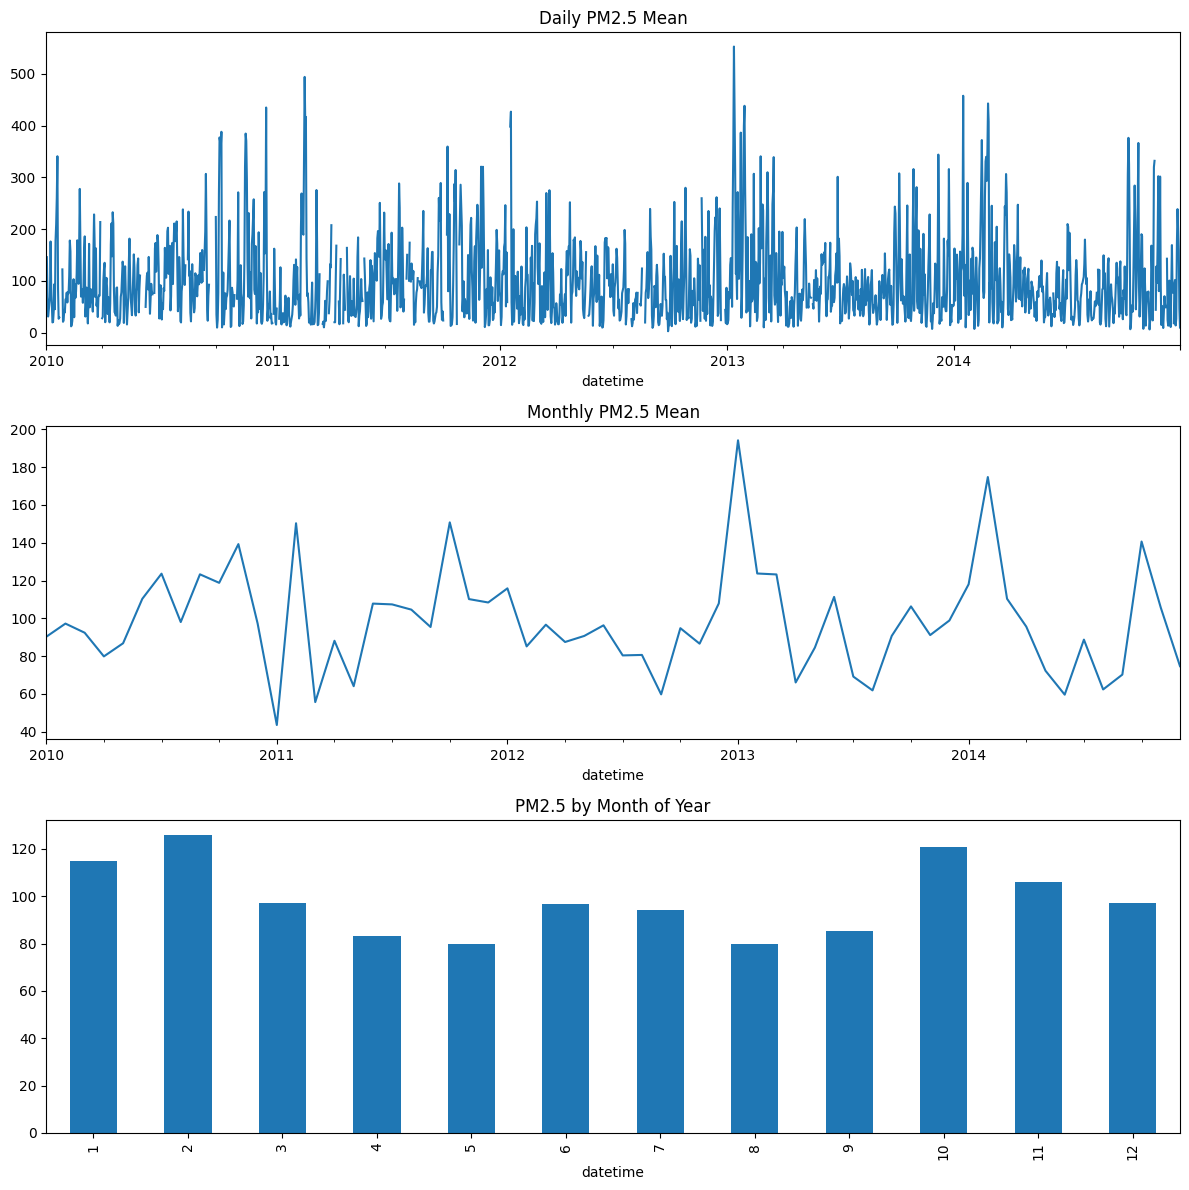

In [ ]:
monthly = daily["pm25_mean"].resample("MS").mean()
seasonal_profile = daily.groupby(daily.index.month)["pm25_mean"].mean()

fig, axes = plt.subplots(3, 1, figsize=(12, 12))

daily["pm25_mean"].plot(ax=axes[0], title="Daily PM2.5 Mean")
monthly.plot(ax=axes[1], title="Monthly PM2.5 Mean")
seasonal_profile.plot(kind="bar", ax=axes[2], title="PM2.5 by Month of Year")

plt.tight_layout()
plt.show()

Q16. Describe the seasonal pattern in the monthly series. Which months are worst, and what weather or human activity might explain this?

Answer: The month-of-year plot shows higher average PM2.5 in February, October, and January, with February the highest. Lower averages appear in May and August. Possible explanations include increased heating emissions and stagnant weather during colder months, along with traffic and industrial emissions. These are possible explanations; the plot alone does not prove the causes.

Q17. Compare pm25_mean and pm25_max for a bad week. Which is better for describing health risk, and why?

Answer: pm25_mean describes the average PM2.5 level, while pm25_max shows the highest hourly level. The mean helps describe overall exposure during the week, but the maximum reveals short, severe pollution peaks. For describing health risk, I would use both: the mean for typical exposure and the maximum to identify potentially harmful peaks.

In [ ]:
from statsmodels.tsa.stattools import adfuller

s = daily["pm25_mean"].interpolate(limit=3).dropna()
s_log = np.log1p(s)
s_d1 = s_log.diff().dropna()
s_d7 = s_log.diff(7).dropna()

print("Skew raw:", round(s.skew(), 2), " log:", round(s_log.skew(), 2))

def adf(x):
    stat, p, *_ = adfuller(x.dropna())
    return round(stat, 2), round(p, 4)

for name, series in {"raw": s, "log": s_log, "diff1": s_d1, "diff7": s_d7}.items():
    print(name, adf(series))

Skew raw: 1.65  log: -0.31


/tmp/ipykernel_698/1698379824.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, *_ = adfuller(x.dropna())
/tmp/ipykernel_698/1698379824.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, *_ = adfuller(x.dropna())


raw (-22.97, 0.0)
log (-24.74, 0.0)
diff1 (-16.01, 0.0)
diff7 (-13.11, 0.0)


/tmp/ipykernel_698/1698379824.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, *_ = adfuller(x.dropna())
/tmp/ipykernel_698/1698379824.py:11: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  stat, p, *_ = adfuller(x.dropna())


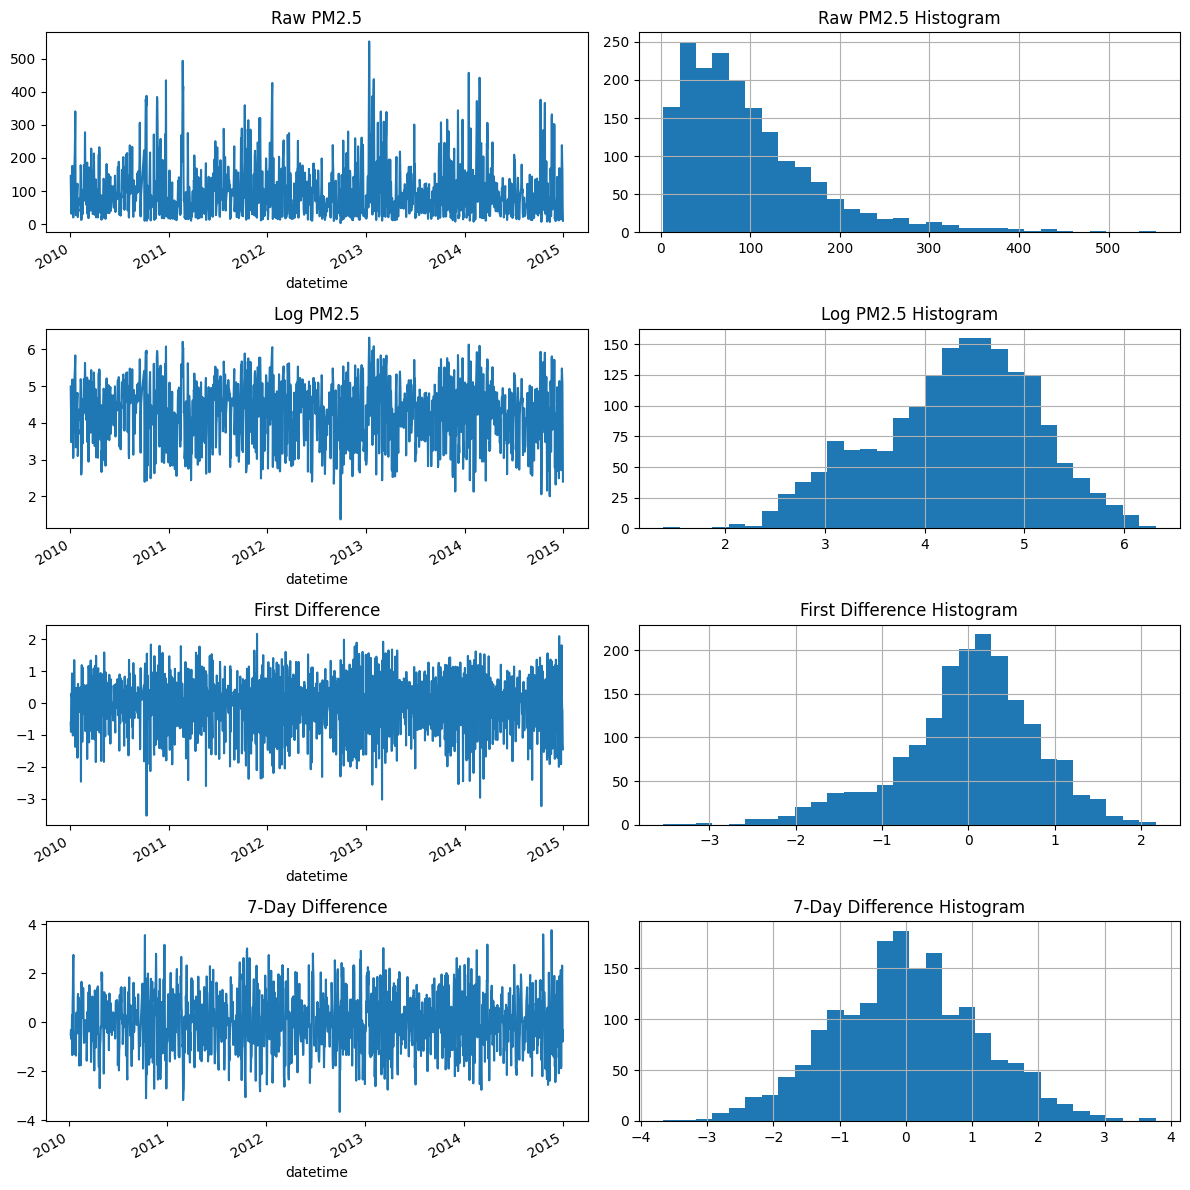

In [ ]:
fig, axes = plt.subplots(4, 2, figsize=(12, 12))

series_list = [
    ("Raw PM2.5", s),
    ("Log PM2.5", s_log),
    ("First Difference", s_d1),
    ("7-Day Difference", s_d7),
]

for row, (name, series) in enumerate(series_list):
    series.plot(ax=axes[row, 0], title=name)
    series.hist(ax=axes[row, 1], bins=30)
    axes[row, 1].set_title(f"{name} Histogram")

plt.tight_layout()
plt.show()

Q18. Why does log1p (and not log) make sense here? What problem would log(0) cause?

Answer: PM2.5 values can be zero, and log1p(x) calculates log(1 + x), so it can handle zero values. Using log(0) is undefined and produces negative infinity. The log transformation also reduces right-skewness: the raw skewness is 1.65, while the log-transformed skewness is -0.31.

Q19. Which series pass the ADF test at the 5% level (p < 0.05)? Does the raw series look stationary to you visually? Reconcile your answer.

Answer: All four series—raw, log, first difference, and 7-day difference—pass the ADF test because their p-values are below 0.05. Visually, the raw series fluctuates around a broadly similar level, but it has large spikes and changing variability. The ADF test provides statistical evidence against a unit root, while the plot shows that the series can still have substantial variation and extreme values.

Q20. What are the downsides of differencing for interpretation, and how do you convert a forecast of differences back to the original scale?

Answer: Differencing removes information about the original level and makes results harder to interpret because they describe changes rather than actual PM2.5 concentrations. To recover the forecast on the log scale, cumulatively add the predicted differences to the last observed log value. Then apply the inverse transformation, expm1, to return to the original PM2.5 scale.

In [ ]:
feat = pd.DataFrame(index=df.index)
feat["pm25"] = df["pm25_interp"]

# Calendar and cyclical features
feat["hour"] = df.index.hour
feat["dow"] = df.index.dayofweek
feat["month"] = df.index.month

feat["hour_sin"] = np.sin(2 * np.pi * feat["hour"] / 24)
feat["hour_cos"] = np.cos(2 * np.pi * feat["hour"] / 24)
feat["month_sin"] = np.sin(2 * np.pi * (feat["month"] - 1) / 12)
feat["month_cos"] = np.cos(2 * np.pi * (feat["month"] - 1) / 12)

# Past-only features
feat["lag_1"] = feat["pm25"].shift(1)
feat["lag_24"] = feat["pm25"].shift(24)
feat["roll24_mean"] = feat["pm25"].shift(1).rolling(24).mean()
feat["temp"] = df["TEMP"]

# Deliberately leaky feature for the leakage demo
feat["roll24_leaky"] = feat["pm25"].rolling(24).mean()

feat = feat.dropna()
print(feat.shape)

(41219, 13)


Q21. Why use sine and cosine for hour instead of the integer 0–23?

Answer:
Sine and cosine represent the hour as a cyclical feature. They show that hour 23 is close to hour 0, unlike integer values, which make them seem far apart. This helps a model understand the daily cycle.

Q22. Explain in your own words why shift(1) comes before .rolling(24) in roll24_mean.

Answer:
shift(1) moves the values back by one hour so the rolling mean uses only the previous 24 hours. This prevents the current hour’s PM2.5 value from being included in its own predictor and avoids data leakage.

In [ ]:
train = feat.loc[:"2013-12-31"]
test = feat.loc["2014-01-01":]
print(len(train), len(test))

32599 8620


In [ ]:
from sklearn.preprocessing import StandardScaler

cols = ["temp", "lag_1", "lag_24", "roll24_mean"]
scaler = StandardScaler().fit(train[cols])  # Fit on training data only
train_scaled = scaler.transform(train[cols])
test_scaled = scaler.transform(test[cols])

def scores(y, yhat):
    return {
        "MAE": round(np.mean(np.abs(y - yhat)), 2),
        "RMSE": round(float(np.sqrt(np.mean((y - yhat) ** 2))), 2)
    }

print("Persistence (lag_1):", scores(test["pm25"], test["lag_1"]))
print("Seasonal naive (lag_24):", scores(test["pm25"], test["lag_24"]))
print("Rolling mean (24h):", scores(test["pm25"], test["roll24_mean"]))
print("LEAKY rolling mean (24h):", scores(test["pm25"], test["roll24_leaky"]))

Persistence (lag_1): {'MAE': np.float64(11.83), 'RMSE': 21.89}
Seasonal naive (lag_24): {'MAE': np.float64(67.05), 'RMSE': 98.24}
Rolling mean (24h): {'MAE': np.float64(42.32), 'RMSE': 62.77}
LEAKY rolling mean (24h): {'MAE': np.float64(40.01), 'RMSE': 59.49}


Q23. After the split in Task 8, compute the RMSE of roll24_leaky as a predictor of pm25 and compare it with roll24_mean. Which looks better, and why is it misleading?

Answer:
The leaky rolling mean looks better because its RMSE is 59.49, compared with 62.77 for the proper rolling mean. However, this is misleading because roll24_leaky includes the current hour’s PM2.5 value in its rolling average. This gives the predictor information it would not have in a real forecast, causing data leakage and making its error appear lower than it should be.

Q24. We call dropna() at the end. What does this do to the first rows of the series, and does it make the index irregular?

Answer:
dropna() removes rows that contain missing values. The first rows are removed because lag and rolling features need earlier hours to calculate their values. It can also remove rows elsewhere in the series, so the datetime index is no longer perfectly regular with one-hour intervals.

Q25. Which baseline is best, and why does persistence work so well for hourly pollution?

Answer:
The persistence baseline (lag_1) is best, with an RMSE of 21.89 and an MAE of 11.83, the lowest errors among the four baselines. It works well because PM2.5 levels often remain similar from one hour to the next, so the previous hour’s value is a useful predictor of the current hour.

Q26. What would go wrong if you fit the scaler on the full dataset before splitting?

Answer:
Fitting the scaler on the full dataset would cause data leakage because information from the test set would influence the scaling parameters, such as the mean and standard deviation. The model would indirectly use information from future data, making its evaluation less reliable. The scaler should be fit on the training set only, then applied to the test set.

Q27. Why is a random 80/20 split inappropriate here? Describe what information would leak into training.

Answer:
A random split would mix earlier and later timestamps, allowing the model to learn from future patterns while predicting the past. A chronological split better reflects real forecasting, where only past data is available for training.

Q28. Any future model you build must beat these baselines. Which number is the one to beat, and why?

Answer:
The number to beat is the persistence baseline’s RMSE of 21.89 (and MAE of 11.83). It is the strongest valid baseline in this comparison, so a future model should achieve lower errors on the same test period.


### Data Preparation Log

| Decision | Alternative Considered | Reason |
|---|---|---|
| Created a datetime index and sorted the data chronologically. | Kept the original row order. | Time-series analysis requires observations to be arranged in time order. |
| Used interpolation to fill missing PM2.5 values, with a limit on consecutive hours. | Forward fill or unrestricted interpolation. | Interpolation had the lowest RMSE in the masking experiment. The limit helps avoid filling long gaps too freely. |
| Added a missing-value indicator. | Filled missing values without marking them. | The indicator helps distinguish originally observed values from imputed values. |
| Checked unusual values and physical constraints. | Automatically removed all flagged values. | Some extreme values may be genuine pollution events, so they should be investigated before removal. |
| Used a chronological train/test split. | Random 80/20 split. | Chronological splitting avoids using future observations to evaluate predictions for an earlier period. |
| Fit the scaler on the training set only. | Fit the scaler on the full dataset. | This prevents information from the test period from leaking into training. |